I completed this assignment without using generative AI.
Completed by Seagar Grubb, 21208009
A. Set up the Physics  
mass of rocket $m = 2.0*10^5 KG$  
Thrust force $F_T = [6.0*10^5, 0, 3.0*10^6] N$  
Gravitational Force $F_g = [0, 0, -mg] N$, $g = 9.81m/s^2$  
A1.  
Net force $F_N = F_T + Fg$  
A2.
$F_N = m*a$  
$F_T + F_g = m*a$  
$a = \frac{(F_T + F_g)}{m}$  
A3.  
The equation in A1 represents the net force on the rocket from gravity and the thruster, and the equation in A2 represents the acceleration of the rocket as a result from the net force.

B. Predict and Calculate  
B1.   
Assuming that the vectors are of the form [x, y, z], with +x being the direction east, +y being north and +z being vertically up, I think that the resultant force vector ($F_N$) will be up and to the east. I know that $F_g$ will point down, which is a -z value, and the value of mg is less than the +z value from $F_T$, resulting in +z for $F_N$.  
B2.   
On paper (Attached/submitted to dropbox)  
B3.   
Drag- Opposes the direction of the rocket, would only mainly be effective during takeoff/in atmosphere. Slows down the rocket relative to how fast the rocket is going.  
Wind-Depending on how the wind blows, can alter the direction of the rocket.

Force of gravity F_G =  [       0.        0. -1962000.]
The net force F_N =  [ 600000.       0. 1038000.]
The acceleration a =  [3.   0.   5.19]
Magnitude of F_N =  1198934.526986357


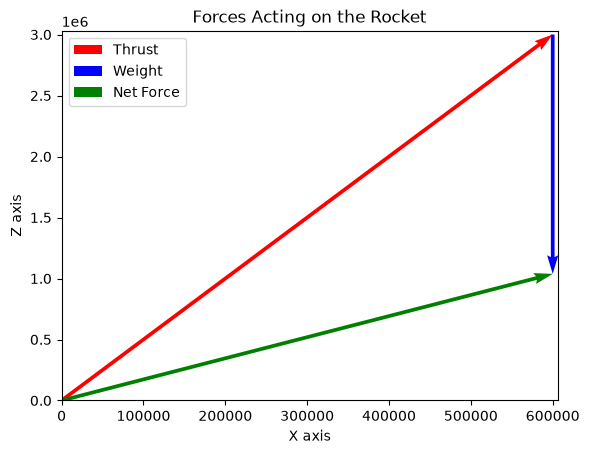

A 2d plot is sufficient to show the forces acting on the rocket, as the forces are all in the x-z plane. The y component of the forces is zero, so a 3d plot is not necessary.


In [ ]:
#C. Build the Computational Model
import numpy as np
import matplotlib.pyplot as plt
import math
m = 2.0*10**5   #Adding the constants (mass and gravity) to the model
g = 9.81
F_T = np.array([6.0*10**5, 0, 3.0*10**6]) #Adding the forces (thrust and weight) to the model as arrays for the computational model
F_G = np.array([0, 0, -m*g])
print ('Force of gravity F_G = ', F_G)
F_N = F_T + F_G   #F_N is the sum of the forces acting on the rocket, which is the thrust minus the weight of the rocket. The net force is then divided by the mass of the rocket to find the acceleration of the rocket
print ("The net force F_N = ", F_N)
a = F_N/m
print ("The acceleration a = ", a)
MagF_N = np.linalg.norm(F_N)  #Calculating the magnitude of the net force acting on the rocket
print("Magnitude of F_N = ", MagF_N)
fig = plt.figure()  #Plotting the forces acting on the rocket using matplotlib, but I had to search up the documentation for the quiver function to plot the vectors. Used matplotlib.org
ax = fig.add_subplot(111)
ax.quiver(0, 0, F_T[0], F_T[2], scale_units='xy', angles='xy', scale=1, color='r', label='Thrust') #Plotting the thrust vector
ax.quiver(F_T[0], F_T[2], F_G[0], F_G[2], scale_units='xy', angles='xy', scale=1, color='b', label='Weight') #Plotting the weight vector, starting from the tip of the thrust vector
ax.quiver(0, 0, F_N[0], F_N[2], scale_units='xy', angles='xy', scale=1, color='g', label='Net Force') #Plotting the net force vector from the origin to the end of F_T + F_g
ax.set_xlim([0, F_T[0]*1.01]) #Setting the limits of the plot
ax.set_ylim([0, F_T[2]*1.01])
ax.set_xlabel('X axis') #Adding labels to the axes based on the given forces, so only x and z axes are needed, as the y component of the forces is zero
ax.set_ylabel('Z axis')
ax.legend() #Adding legend to the plot to identify the vectors
ax.set_title('Forces Acting on the Rocket')
plt.show()
print ('A 2d plot is sufficient to show the forces acting on the rocket, as the forces are all in the x-z plane. The y component of the forces is zero, so a 3d plot is not necessary.')

In [3]:
print ('% horizontal force is ', F_N[0]**2/np.linalg.norm(F_N)**2)
print ('% vertical force is ', F_N[2]**2/np.linalg.norm(F_N)**2)
print ('thrust to weight ratio is ',np.linalg.norm(F_T)/np.linalg.norm(F_G))

% horizontal force is  0.2504445390568259
% vertical force is  0.7495554609431743
thrust to weight ratio is  1.5593331845849494


D. Check, Interpret and Assess  
D1. Yes the values I calculated for $F_N$ and $a$ align with the computational model. I rounded down to 2 sig figs though, which caused some discrepency, but if I followed through with unrounded values they would agree.  
D2. The acceleration is + for the x and z values, so assuming z is up, it will gain height and speed at $+5.19\frac{m}{s^2}$. Previously, i said that +x is east, so the rocket is accelerating at $+3\frac{m}{s^2}$. These makes sense because a rocket you would hope is accelerating up, along with sideways to help achieve orbital speed.    
D3. The constants given (mass and F_T) were a bit on the small side for the average rocket, but I think a more important evaluation is the thrust to weight ratio. The thrust to weight ratio is 1.59, similar to the T:W for the Ariane 62, which is 1.6. So, overall I would say the specs of the model rocket in this activity is pretty accurate, other than the thrust vector. The direction of the thrust was mostly vertical at 75% vs 25% horizontal, which would occur early in the tilt manuever but immediately after launch, it is roughly 100% vertical. I think that the thrust force should be more vertical, especially if this is supposed to be immediately after launch. I would remove the thrust in the x direction, or at least reduce it signficiantly for immediately after launch. 
https://www.eoportal.org/other-space-activities/ariane6  


The angle is 2.0
F_T is [ 293155.77230101       0.         8394882.9469604 ]
F_G is [       0.        0. -5199300.]
F_N is [ 293155.77230101       0.         3195582.9469604 ]
The accelleration is [0.5531241  0.         6.02940179]


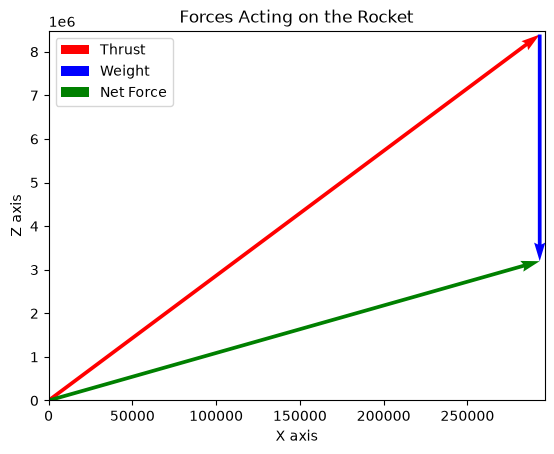

In [28]:
# E. Extend model
# A significant adjustment I will make is adding an angle component to the model to calculate the different forces at each stage in the flight
# I will use the values of the Ariane 62 rocket for m and F_T
# As the rocket is launched and it begins its pitch manuever, the angle of thrust changes from vertical to horizontal
# I will keep the magnitude of the thrust force the same throughout, with it slowly going towards being mostly horizontal
# I will add an input degrees so that you can see the force and acceleration distribution at a specific angle from liftoff (0) to orbit (90)
# It will remain 2-dimensional as the I will only have the angle change its horizontal component in the +x direction
import numpy as np
import matplotlib.pyplot as plt
import math
m = 5.3*10**5
g = 9.81
F_T = np.zeros(3)
MagF_T = 8.4*10**6 
F_G = np.array ([0, 0, -m*g])
theta = (float(input("Please input angle (degrees) relative to the vertical"))) #Input angle in degrees
F_T [0] = MagF_T*math.sin(math.radians(theta))  #The angle changes the thrust slightly, so that it will change direction
F_T [2] = MagF_T*math.cos(math.radians(theta))
F_N = F_T + F_G
a = F_N/m
print ('The angle is', theta)
print ("F_T is", F_T)
print ("F_G is", F_G)
print ("F_N is", F_N)
print ('The accelleration is', a)
fig = plt.figure()  #Plotting the forces acting on the rocket
ax = fig.add_subplot(111)
ax.quiver(0, 0, F_T[0], F_T[2], scale_units='xy', angles='xy', scale=1, color='r', label='Thrust') #Plotting the thrust vector
ax.quiver(F_T[0], F_T[2], F_G[0], F_G[2], scale_units='xy', angles='xy', scale=1, color='b', label='Weight') #Plotting the weight vector, starting from the tip of the thrust vector
ax.quiver(0, 0, F_N[0], F_N[2], scale_units='xy', angles='xy', scale=1, color='g', label='Net Force') #Plotting the net force vector from the origin to the end of F_T + F_g
ax.set_xlim([min(0,F_N[0],F_T[0])*1.01, max(0,F_N[0],F_T[0])*1.01]) #Setting the limits of the plot, has to be able to change to the needs of the vectors
ax.set_ylim([min(0,F_T[2],F_N[2])*1.01, max(0,F_T[2],F_N[2])*1.01])
ax.set_xlabel('X axis') #Adding labels to the axes based on the given forces, so only x and z axes are needed, as the y component of the forces is zero
ax.set_ylabel('Z axis')
ax.legend() #Adding legend to the plot to identify the vectors
ax.set_title('Forces Acting on the Rocket')
plt.show()

E. 
I changed the mass and thrust values to be modelled after the Ariane 62 rocket, and added another variable, theta, to be able to calculate the thrust and forces at each stage of the flight, with theta being the angle relative to the normal/vertical. The fact that the magnitude of the thrust is constant is a downside to the model, as this assumption disregards the fact that at later stages in flight (like when it reaches orbit), its thrust vector is a lot smaller as the boosters run out of fuel. I would think that the model is more accurate at smaller angles when the rocket is initially taking off than later in its trajectory, because of the fact the magnitude of the thrust does not change.

F. Reflect
F1. Linear Algebra appeared with the scaling and addition of vectors at the start of each model. The scaling occured when accelleration was calculated, when the $F_N$ vector was scaled by $\frac{1}{m}$. The acceleration of the physical system tells us how the velocity of the rocket is changing. Addition occured with $F_N = F_g + F_T$, which tells us how the overall force is being applied to the rocket.
F2. I think that the only thing was understanding where to start/finish each vector with the quiver function. You have to understand what is physically going on, and how to properly show it with the quiver function. Code alone may not properly represent the physical picture, with like which vector(s) should be tip-to-tail, etc. I think that the most important check was just simply looking at the final figure, which shows the addition of the vectors. 
F3. Adding drag would be the most difficult. You would need comparable drag coefficients of different rockets, along with the cross-sectional area of those rockets to properly calculate it. Also, you would need to add a time component to the model, as drag is based off of the velocity vector of the rocket. You would need to know how drag works, especially with the fact at higher altitudes, air also gets thinner and such, so a position vector would also be needed. Some resources I used was ESA to look up specs for the Ariane 62 rocket, and the Glenn Research Center to look into the different phases of the launch, like the pitch maneuver. I think that AI could have helped with researching rockets with similar specs to the specifications given at the beginning of the assignment a lot easier and faster. AI can simply browse files and sites faster than I could with better retention.